# Laboratorio 4: Regresion lineal y gradiente descendente

**Nombre:** Laura Ostos

**C.C:** 1010107809


      x    y
0  0.00  0.0
1  0.25  0.5
2  0.50  1.0
3  0.75  1.5
4  1.00  2.0


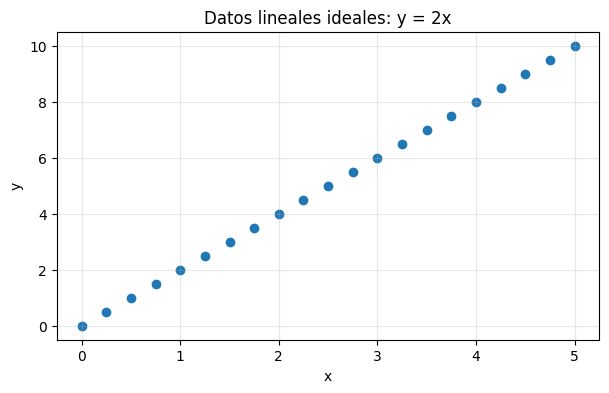

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.linear_model import HuberRegressor

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(42)

# ==========================================================================================

# 1. construccion DataFrame
x = np.linspace(0, 5, 21)
df = pd.DataFrame({"x": x, "y": 2 * x})
print(df.head())

plt.scatter(df.x, df.y, color="tab:blue")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Datos lineales ideales: y = 2x")
plt.show()


In [ ]:
# 2. funcion de coste cuadratica
def costo(theta0, theta1, x, y): # Coste cuadratico J(theta0, theta1) para un par de parametros.
    m = len(y)
    pred = theta0 + theta1 * x
    return np.sum((pred - y) ** 2) / (2 * m)


def costo_malla(T0, T1, x, y): #T0 y T1 son arreglos de la misma forma (p. ej. de meshgrid).
    m = len(y)
    pred = T0[..., None] + T1[..., None] * x          # (..., m)
    return np.sum((pred - y) ** 2, axis=-1) / (2 * m)


def costo_matricial(theta, x, y):   # Lambda = Theta^T X, con X de dimension (2, m).
    m = len(y)
    X = np.vstack([np.ones(m), x])
    Lam = theta @ X
    return np.sum((Lam - y) ** 2) / (2 * m)


#las tres versiones deben coincidir
th = np.array([0.5, 1.7])
print("las tres versiones deben coincidir:")
print(costo(*th, x, df.y.values))
print(costo_malla(np.array(th[0]), np.array(th[1]), x, df.y.values))
print(costo_matricial(th, x, df.y.values))

las tres versiones deben coincidir:
0.13437500000000013
0.13437500000000013
0.13437500000000013


theta1 que minimiza J: 2.000   J_min = 0.00e+00


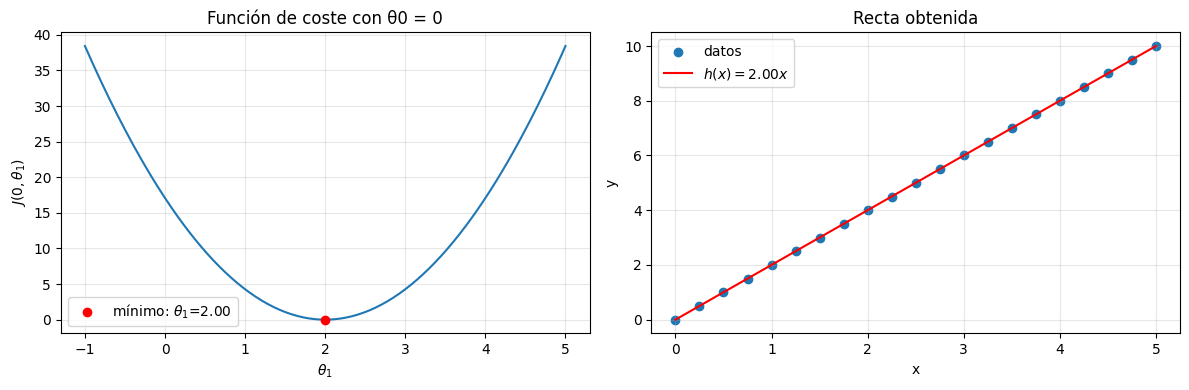

In [ ]:
# 3. caso de un parametro theta0 = 0
y_ideal = df.y.values
theta1_val = np.linspace(-1, 5, 241)
J_val = np.array([costo(0, t1, x, y_ideal) for t1 in theta1_val])

i_min = np.argmin(J_val)
theta1_mejor = theta1_val[i_min]
print(f"theta1 que minimiza J: {theta1_mejor:.3f}   J_min = {J_val[i_min]:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(theta1_val, J_val)
ax[0].plot(theta1_mejor, J_val[i_min], "ro", label=fr"mínimo: $\theta_1$={theta1_mejor:.2f}")
ax[0].set_xlabel(r"$\theta_1$"); ax[0].set_ylabel(r"$J(0,\theta_1)$")
ax[0].set_title("Función de coste con θ0 = 0"); ax[0].legend()

ax[1].scatter(x, y_ideal, label="datos")
xx = np.linspace(0, 5, 100)
ax[1].plot(xx, theta1_mejor * xx, "r", label=fr"$h(x)={theta1_mejor:.2f}x$")
ax[1].set_xlabel("x"); ax[1].set_ylabel("y"); ax[1].set_title("Recta obtenida"); ax[1].legend()
plt.tight_layout(); plt.show()

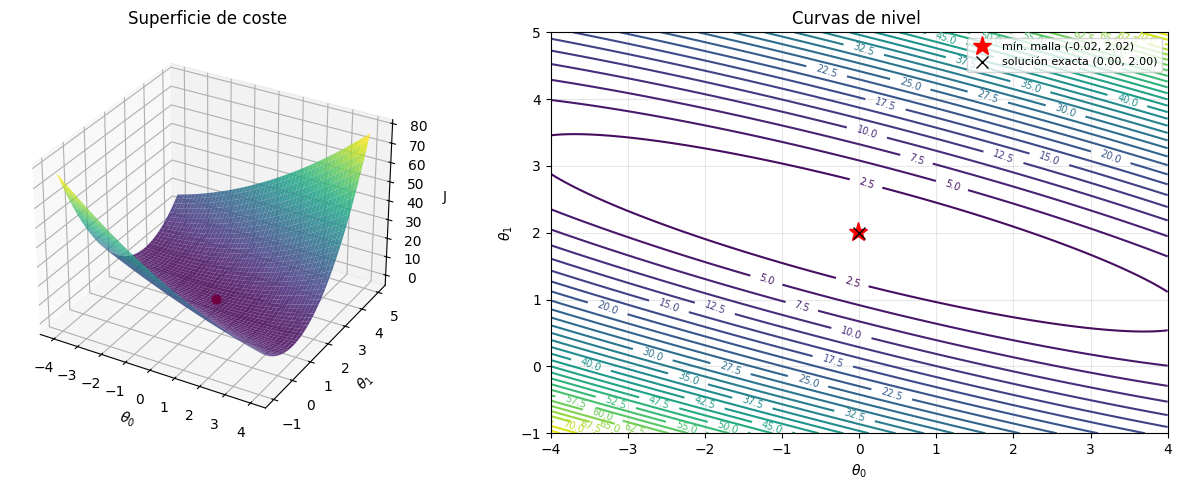

Mínimo en la malla: theta0=-0.020, theta1=2.015, J=4.15e-04


In [ ]:
# 4. dos parametros (theta0 y theta1 variasn) para hallar superficie y curvas de nivel
def ajuste(x, y): # Minimo exacto de J, theta1 = Cov(x,y)/Var(x), theta0 = ybar - theta1*xbar.
    th1 = np.cov(x, y, bias=True)[0, 1] / np.var(x)
    th0 = y.mean() - th1 * x.mean()
    return th0, th1

def superficie(x, y, t0_rng, t1_rng, titulo="", n=200, elev=30, azim=-60): # Dibuja superficie 3D y  curvas de nivel de J
    t0 = np.linspace(*t0_rng, n)
    t1 = np.linspace(*t1_rng, n)
    T0, T1 = np.meshgrid(t0, t1)
    J = costo_malla(T0, T1, x, y)

    j = np.unravel_index(np.argmin(J), J.shape)
    t0_min, t1_min, J_min = T0[j], T1[j], J[j]
    c0, c1 = ajuste(x, y)

    fig = plt.figure(figsize=(13, 5))
    ax3 = fig.add_subplot(1, 2, 1, projection="3d")
    ax3.plot_surface(T0, T1, J, cmap=cm.viridis, alpha=0.85, linewidth=0)
    ax3.scatter([t0_min], [t1_min], [J_min], color="r", s=40)
    ax3.set_xlabel(r"$\theta_0$"); ax3.set_ylabel(r"$\theta_1$"); ax3.set_zlabel("J")
    ax3.set_title("Superficie de coste "); ax3.view_init(elev, azim)

    ax2 = fig.add_subplot(1, 2, 2)
    cs = ax2.contour(T0, T1, J, levels=30, cmap="viridis")
    ax2.clabel(cs, inline=True, fontsize=7)
    ax2.plot(t0_min, t1_min, "r*", ms=14, label=f"mín. malla ({t0_min:.2f}, {t1_min:.2f})")
    ax2.plot(c0, c1, "kx", ms=9, label=f"solución exacta ({c0:.2f}, {c1:.2f})")
    ax2.set_xlabel(r"$\theta_0$"); ax2.set_ylabel(r"$\theta_1$")
    ax2.set_title("Curvas de nivel "); ax2.legend(loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()
    return t0_min, t1_min, J_min

t0_m, t1_m, J_m = superficie(x, y_ideal, (-4, 4), (-1, 5))
print(f"Mínimo en la malla: theta0={t0_m:.3f}, theta1={t1_m:.3f}, J={J_m:.2e}")


In [ ]:
# 5. interpretacion geometrica
print("5. Interpretación geomettrica:")
print("La superficie de J(theta0, theta1) es un paraboloide elíptico y es convexa ")
print("Existe un unico minimo y es global en (theta0, theta1)= (0,2) con J=0")
print("Las curvas de nivel son elipses centradas en el minimo, son elipses inclinadas y alargadas")


5. Interpretación geomettrica:
La superficie de J(theta0, theta1) es un paraboloide elíptico y es convexa 
Existe un unico minimo y es global en (theta0, theta1)= (0,2) con J=0
Las curvas de nivel son elipses centradas en el minimo, son elipses inclinadas y alargadas


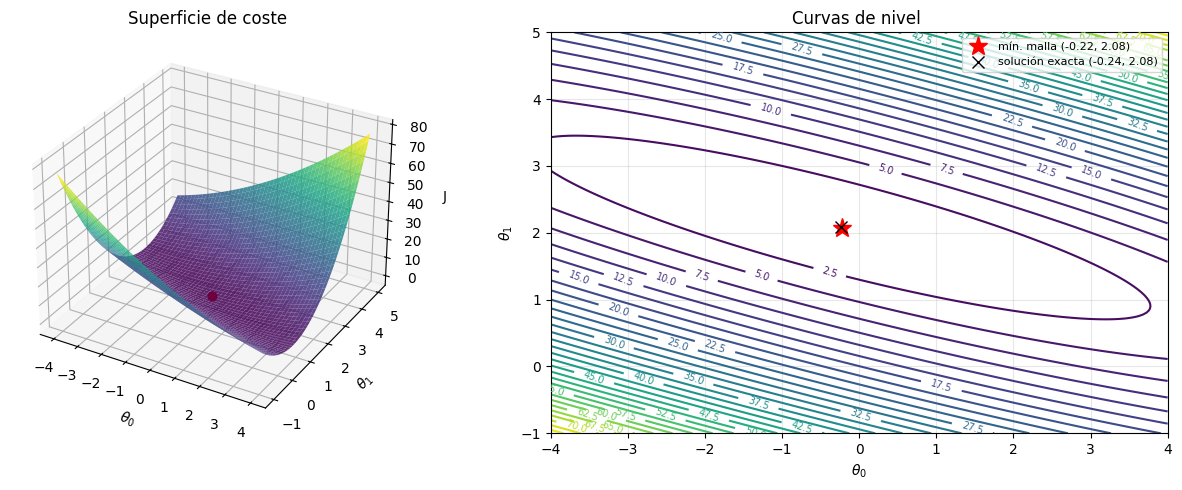

             theta0    theta1  J mínimo
ideal     -0.020101  2.015075  0.000415
con ruido -0.221106  2.075377  0.335825
Solucion exacta con ruido: theta0=-0.240, theta1=2.080


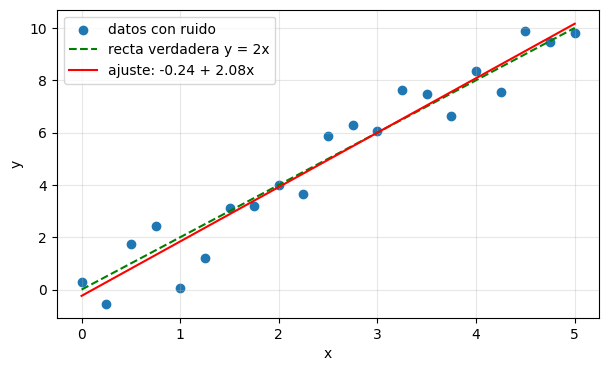

6.Comparación:
La forma de la superficie no cambia
El minimo ya no es cero, J es mayor que 0 y el minimo se dezplaza con respecto a (0,2)


In [ ]:
# 6. datos con ruido
rng = np.random.default_rng(42)
y_ruido = 2 * x + rng.normal(0, 1.0, size=x.size)
df_ruido = pd.DataFrame({"x": x, "y": y_ruido})

t0_n, t1_n, J_n = superficie(x, y_ruido, (-4, 4), (-1, 5), "(datos con ruido)")
c0, c1 = ajuste(x, y_ruido)

comp = pd.DataFrame({
    "theta0": [t0_m, t0_n], "theta1": [t1_m, t1_n], "J mínimo": [J_m, J_n]},
    index=["ideal", "con ruido"])
print(comp)
print(f"Solucion exacta con ruido: theta0={c0:.3f}, theta1={c1:.3f}")

xx = np.linspace(0, 5, 100)
plt.scatter(x, y_ruido, label="datos con ruido")
plt.plot(xx, 2 * xx, "g--", label="recta verdadera y = 2x")
plt.plot(xx, c0 + c1 * xx, "r", label=f"ajuste: {c0:.2f} + {c1:.2f}x")
plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.show()

print("6.Comparación:")
print("La forma de la superficie no cambia")
print("El minimo ya no es cero, J es mayor que 0 y el minimo se dezplaza con respecto a (0,2)")



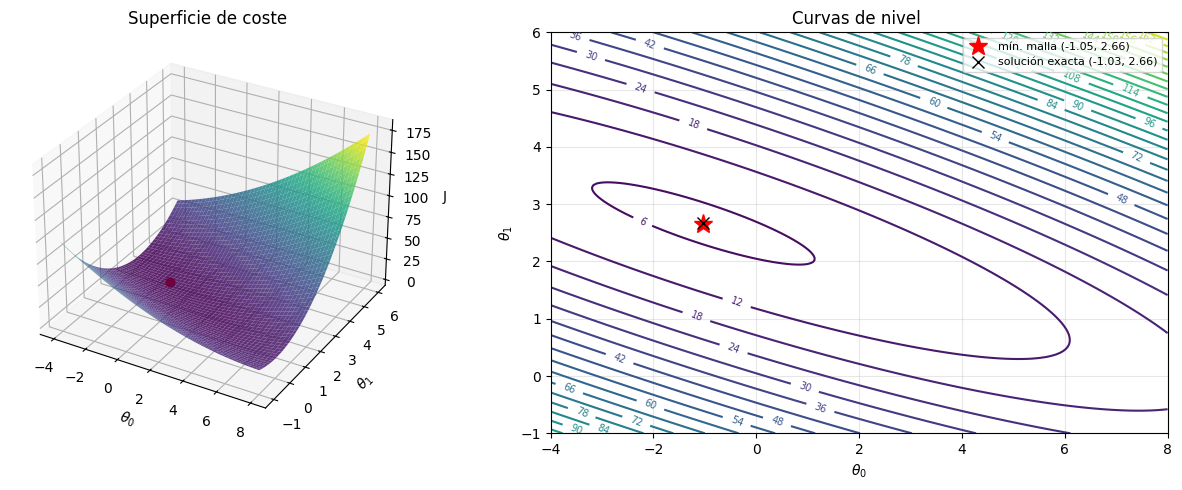

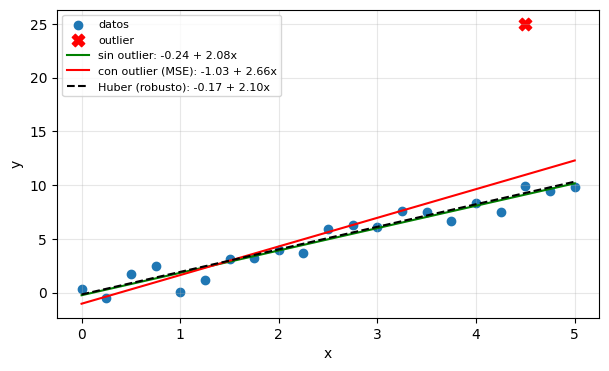

                     theta0    theta1
sin outlier       -0.239665  2.079799
con outlier (MSE) -1.030046  2.663465
Huber             -0.167816  2.097148
7.Discución:
Un solo punto desplaza de forma notable la recta (cambian tanto la pendiente como el intercepto) y sube el coste mínimo.
Limitaciones: es **sensible a valores atípicos** (no es robusta) y asume errores con distribución aproximadamente normal y varianza constante.
Alternativas: error absoluto medio (MAE), pérdida de Huber (que se muestra arriba y casi ignora el outlier), o detectar y tratar los outliers antes de ajustar.


In [ ]:
#7. Con un valor atipico
x_1 = np.append(x, 4.5)
y_1 = np.append(y_ruido, 25.0)

t0_o, t1_o, J_o = superficie(x_1, y_1, (-4, 8), (-1, 6), "(con outlier)")
o0, o1 = ajuste(x_1, y_1)

hub = HuberRegressor().fit(x_1.reshape(-1, 1), y_1)

plt.scatter(x, y_ruido, label="datos")
plt.scatter([4.5], [25], color="red", s=80, marker="X", label="outlier")
plt.plot(xx, c0 + c1 * xx, "g", label=f"sin outlier: {c0:.2f} + {c1:.2f}x")
plt.plot(xx, o0 + o1 * xx, "r", label=f"con outlier (MSE): {o0:.2f} + {o1:.2f}x")
plt.plot(xx, hub.intercept_ + hub.coef_[0] * xx, "k--",label=f"Huber (robusto): {hub.intercept_:.2f} + {hub.coef_[0]:.2f}x")
plt.legend(fontsize=8); plt.xlabel("x"); plt.ylabel("y"); plt.show()

print(pd.DataFrame({"theta0": [c0, o0, hub.intercept_], "theta1": [c1, o1, hub.coef_[0]]},index=["sin outlier", "con outlier (MSE)", "Huber"]))
print("7.Discución:")
print("Un solo punto desplaza de forma notable la recta (cambian tanto la pendiente como el intercepto) y sube el coste mínimo.")
print("Limitaciones: es **sensible a valores atípicos** (no es robusta) y asume errores con distribución aproximadamente normal y varianza constante.")
print("Alternativas: error absoluto medio (MAE), pérdida de Huber (que se muestra arriba y casi ignora el outlier), o detectar y tratar los outliers antes de ajustar.")


Ajuste lineal: theta0=-3.863, theta1=4.884, J_min=1.796, R²=0.938
Ajuste cuadratico: J_min=0.052


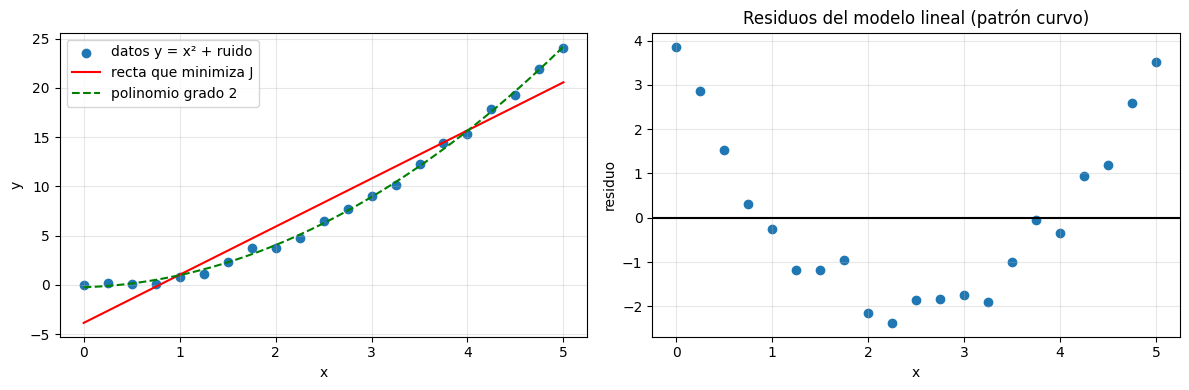

8.Discución:
Minimizar J solo garantiza el mejor modelo dentro de la familia elegida (restas), no que esa familia sea adecuada.
Los residuos muestran un patron en forma de u, el modelo subestima en los extremos y sobreestima en el centro, hay sesgo (underfitting)


In [ ]:
# 8. modelo lineal sobre datos NO lineales
rng = np.random.default_rng(7)
y_nl = x**2 + rng.normal(0, 0.5, size=x.size)

n0, n1 = ajuste(x, y_nl)
pred_nl = n0 + n1 * x
residuos = y_nl - pred_nl
R2 = 1 - np.sum(residuos**2) / np.sum((y_nl - y_nl.mean()) ** 2)
J_nl = costo(n0, n1, x, y_nl)
print(f"Ajuste lineal: theta0={n0:.3f}, theta1={n1:.3f}, J_min={J_nl:.3f}, R²={R2:.3f}")

# Contraste con modelo cuadratico
coef2 = np.polyfit(x, y_nl, 2)
res2 = y_nl - np.polyval(coef2, x)
J_quad = np.sum(res2**2) / (2 * len(x))
print(f"Ajuste cuadratico: J_min={J_quad:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(x, y_nl, label="datos y = x² + ruido")
ax[0].plot(xx, n0 + n1 * xx, "r", label="recta que minimiza J")
ax[0].plot(xx, np.polyval(coef2, xx), "g--", label="polinomio grado 2")
ax[0].legend(); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[1].scatter(x, residuos); ax[1].axhline(0, color="k")
ax[1].set_title("Residuos del modelo lineal (patrón curvo)"); ax[1].set_xlabel("x"); ax[1].set_ylabel("residuo")
plt.tight_layout(); plt.show()

print("8.Discución:")
print("Minimizar J solo garantiza el mejor modelo dentro de la familia elegida (restas), no que esa familia sea adecuada.")
print("Los residuos muestran un patron en forma de u, el modelo subestima en los extremos y sobreestima en el centro, hay sesgo (underfitting)")

## 9. Expresion teorica de la funcion de coste y de sus minimos

Notacion: $\bar x=\frac1m\sum x^{(i)}$, $\bar y=\frac1m\sum y^{(i)}$, $\overline{x^2}=\frac1m\sum (x^{(i)})^2$, $\overline{xy}=\frac1m\sum x^{(i)}y^{(i)}$, $\overline{y^2}=\frac1m\sum (y^{(i)})^2$.

**Un parametro ($\theta_0=0$)**

$$J(\theta_1)=\frac1{2m}\sum(\theta_1x^{(i)}-y^{(i)})^2=\frac12\left[\overline{x^2}\,\theta_1^2-2\,\overline{xy}\,\theta_1+\overline{y^2}\right]$$

Es una parabola que abre hacia arriba (si $\overline{x^2}>0$). Derivando:

$$\frac{dJ}{d\theta_1}=\overline{x^2}\,\theta_1-\overline{xy}=0\ \Rightarrow\ \theta_1^*=\frac{\overline{xy}}{\overline{x^2}}=\frac{\sum x^{(i)}y^{(i)}}{\sum (x^{(i)})^2},\qquad \frac{d^2J}{d\theta_1^2}=\overline{x^2}>0$$

La segunda derivada positiva confirma que es un minimo. Geometricamente, es la pendiente de la recta que pasa por el origen que mejor ajusta los datos.

**Dos parámetros**

$$J(\theta_0,\theta_1)=\frac12\left[\theta_0^2+2\bar x\,\theta_0\theta_1+\overline{x^2}\,\theta_1^2-2\bar y\,\theta_0-2\,\overline{xy}\,\theta_1+\overline{y^2}\right]$$

Es un paraboloide eliptico. Igualando el gradiente a cero se obtienen las ecuaciones normales:

$$\frac{\partial J}{\partial\theta_0}=\theta_0+\bar x\,\theta_1-\bar y=0,\qquad
\frac{\partial J}{\partial\theta_1}=\bar x\,\theta_0+\overline{x^2}\,\theta_1-\overline{xy}=0$$

cuya solucion es

$$\theta_1^*=\frac{\overline{xy}-\bar x\,\bar y}{\overline{x^2}-\bar x^2}=\frac{\operatorname{Cov}(x,y)}{\operatorname{Var}(x)},\qquad \theta_0^*=\bar y-\theta_1^*\bar x$$

El Hessiano es

$$H=\begin{pmatrix}1&\bar x\\ \bar x&\overline{x^2}\end{pmatrix},\qquad \det H=\overline{x^2}-\bar x^2=\operatorname{Var}(x)>0$$

Como $\operatorname{tr}H>0$ y $\det H>0$, $H$ es definido positivo: J es estrictamente convexa y el punto crítico es el minimo global unico.

**Interpretación del minimo.** La recta optima pasa por el centroide $(\bar x,\bar y)$ de los datos (por la primera ecuación normal), y su pendiente es la covarianza entre $x$ e $y$ normalizada por la varianza de $x$. Los valores propios de $H$ fijan la curvatura (los ejes de las elipses); el cociente entre el mayor y el menor (número de condición) determina qué tan lento converge el gradiente descendente.

In [ ]:
for nombre, yy in [("ideal", y_ideal), ("ruido", y_ruido), ("outlier", y_1)]:
    xx_ = x if nombre != "outlier" else x_1
    # un parametro
    t1_teo = np.sum(xx_ * yy) / np.sum(xx_**2)
    # dos parametros (ecuaciones normales resueltas con algebra lineal)
    xb, yb, x2b, xyb = xx_.mean(), yy.mean(), (xx_**2).mean(), (xx_ * yy).mean()
    H = np.array([[1, xb], [xb, x2b]])
    sol = np.linalg.solve(H, np.array([yb, xyb]))
    print(f"{nombre:8s} | theta1(θ0=0)={t1_teo:7.4f} | (θ0,θ1)={sol.round(4)} | "
          f"cerrado={np.round(ajuste(xx_, yy), 4)} | det H={np.linalg.det(H):.3f} "
          f"| autovalores H={np.linalg.eigvalsh(H).round(3)}")

ideal    | theta1(θ0=0)= 2.0000 | (θ0,θ1)=[0. 2.] | cerrado=[0. 2.] | det H=2.292 | autovalores H=[0.247 9.295]
ruido    | theta1(θ0=0)= 2.0097 | (θ0,θ1)=[-0.2397  2.0798] | cerrado=[-0.2397  2.0798] | det H=2.292 | autovalores H=[0.247 9.295]
outlier  | theta1(θ0=0)= 2.3694 | (θ0,θ1)=[-1.03    2.6635] | cerrado=[-1.03    2.6635] | det H=2.361 | autovalores H=[0.24  9.834]


,alpha,iteraciones,x final,|x-4|,estado
0,0.01,605,3.999951e+00,4.917856e-05,converge
1,0.10,55,3.999953e+00,4.676805e-05,converge
2,0.50,1,4.000000e+00,0.000000e+00,converge
3,0.90,55,4.000047e+00,4.676805e-05,converge
4,1.00,10000,-6.000000e+00,1.000000e+01,no converge (oscila)
5,1.10,139,1.014363e+12,1.014363e+12,diverge


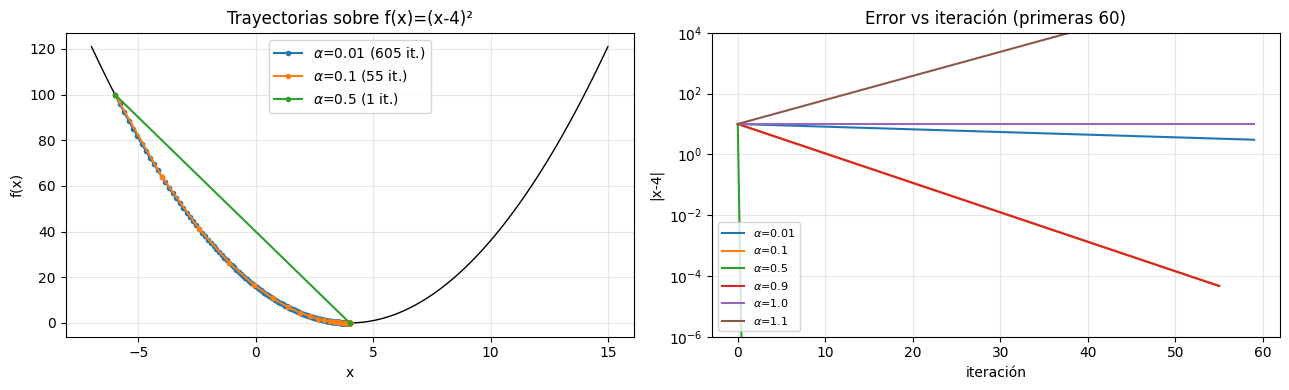

In [ ]:
# 10. gradiente descendente en 1D
def gradiente_1d(df, w0, alpha, eps=1e-4, max_iter=10_000): # Devuelve (w_final, historial, convergio).
    w = w0
    hist = [w]
    for _ in range(max_iter):
        g = df(w)
        if abs(g) < eps:
            return w, np.array(hist), True
        w = w - alpha * g
        hist.append(w)
        if not np.isfinite(w) or abs(w) > 1e12:   # divergencia
            return w, np.array(hist), False
    return w, np.array(hist), False


f = lambda x: (x - 4) ** 2
df = lambda x: 2 * (x - 4)

w0 = -6.0
alphas = [0.01, 0.1, 0.5, 0.9, 1.0, 1.1]
filas, trayectorias = [], {}
for a in alphas:
    w, h, ok = gradiente_1d(df, w0, a)
    trayectorias[a] = h
    estado = "converge" if ok else ("diverge" if abs(w) > 1e6 else "no converge (oscila)")
    filas.append({"alpha": a, "iteraciones": len(h) - 1, "x final": w,
                  "|x-4|": abs(w - 4), "estado": estado})
display(pd.DataFrame(filas))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
xs = np.linspace(-7, 15, 300)
ax[0].plot(xs, f(xs), "k", lw=1)
for a in [0.01, 0.1, 0.5]:
    h = trayectorias[a]
    ax[0].plot(h, f(h), "o-", ms=3, label=fr"$\alpha$={a} ({len(h)-1} it.)")
ax[0].set_xlabel("x"); ax[0].set_ylabel("f(x)"); ax[0].set_title("Trayectorias sobre f(x)=(x-4)²"); ax[0].legend()

for a in alphas:
    h = trayectorias[a][:60]
    ax[1].plot(np.abs(h - 4) + 1e-16, label=fr"$\alpha$={a}")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-6, 1e4)
ax[1].set_xlabel("iteración"); ax[1].set_ylabel("|x-4|"); ax[1].set_title("Error vs iteración (primeras 60)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

numérico : [-0.52000224 -0.05756847] 
analítico: [-0.52000224 -0.05756847]


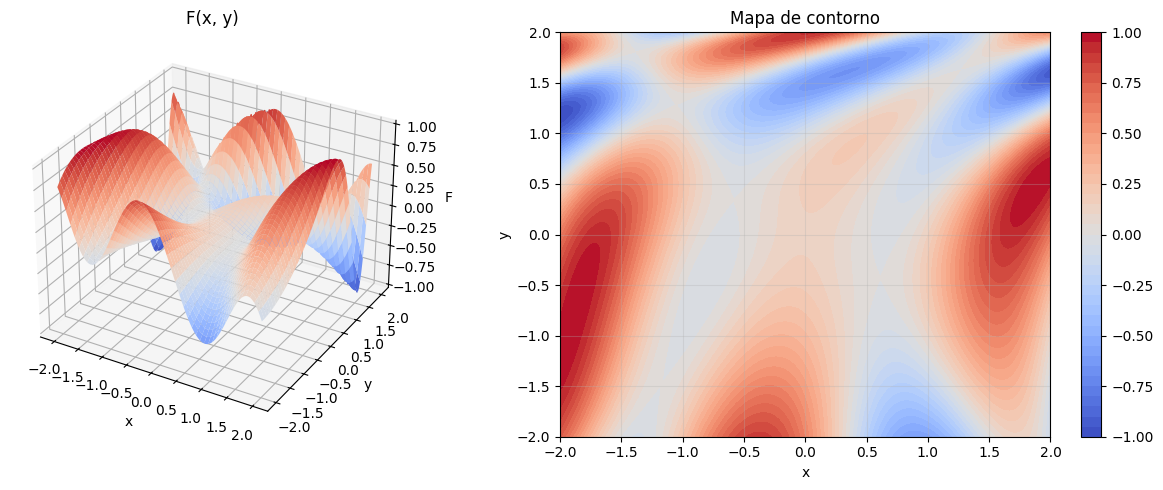

In [ ]:
# 11. minimo de F(x,y)
def F(x, y):
    return np.sin(0.5 * x**2 - 0.25 * y**2 + 3) * np.cos(2 * x + 1 - np.exp(y))

def grad_F(x, y):
    A = 0.5 * x**2 - 0.25 * y**2 + 3
    B = 2 * x + 1 - np.exp(y)
    dFx = x * np.cos(A) * np.cos(B) - 2 * np.sin(A) * np.sin(B)
    dFy = -0.5 * y * np.cos(A) * np.cos(B) + np.exp(y) * np.sin(A) * np.sin(B)
    return np.array([dFx, dFy])

# Verificacion del gradiente con diferencias finitas centradas
p, h = np.array([0.3, -0.7]), 1e-6
num = np.array([(F(p[0] + h, p[1]) - F(p[0] - h, p[1])) / (2 * h), (F(p[0], p[1] + h) - F(p[0], p[1] - h)) / (2 * h)])
print("numérico :", num, "\nanalítico:", grad_F(*p))

# Grafica 3D y contornos
gx = np.linspace(-2, 2, 300); gy = np.linspace(-2, 2, 300)
GX, GY = np.meshgrid(gx, gy); GZ = F(GX, GY)

fig = plt.figure(figsize=(13, 5))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
ax3.plot_surface(GX, GY, GZ, cmap="coolwarm", linewidth=0, antialiased=True)
ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("F"); ax3.set_title("F(x, y)")
ax2 = fig.add_subplot(1, 2, 2)
cf = ax2.contourf(GX, GY, GZ, levels=40, cmap="coolwarm"); plt.colorbar(cf, ax=ax2)
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_title("Mapa de contorno")
plt.tight_layout(); plt.show()

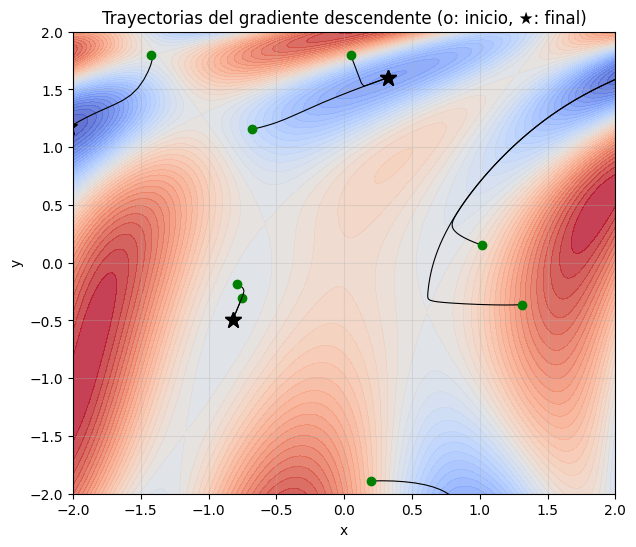

,inicio,"mínimo (x,y)",F,|∇F|,iteraciones
0,"[-1.42, 1.79]","[-2.028, 1.172]",-1.000000,8.139421e-08,85
1,"[1.01, 0.15]","[2.202, 1.687]",-1.000000,8.746725e-08,219
2,"[1.31, -0.36]","[2.202, 1.687]",-1.000000,9.045937e-08,438
3,"[0.2, -1.89]","[1.1, -2.852]",-1.000000,9.801080e-08,231
4,"[0.05, 1.8]","[0.323, 1.602]",-0.657400,9.762911e-08,422
5,"[-0.68, 1.15]","[0.323, 1.602]",-0.657400,9.939429e-08,469
6,"[-0.79, -0.19]","[-0.823, -0.499]",-0.041983,9.949287e-08,1465
7,"[-0.75, -0.31]","[-0.823, -0.499]",-0.041983,9.974504e-08,1419


Mejor mínimo encontrado: (x, y) = [-2.028  1.172],  F = -1.000000


In [ ]:
def gradiente_2d(grad, p0, alpha=0.05, tol=1e-7, max_iter=20_000, caja=3.0):
    p = np.array(p0, float)
    camino = [p.copy()]
    for _ in range(max_iter):
        g = grad(*p)
        if np.linalg.norm(g) < tol:
            break
        p = np.clip(p - alpha * g, -caja, caja)
        camino.append(p.copy())
    return p, np.array(camino)


rng = np.random.default_rng(1)
inicios = rng.uniform(-2, 2, size=(8, 2))
resultados = []
fig, ax = plt.subplots(figsize=(7, 6))
cf = ax.contourf(GX, GY, GZ, levels=40, cmap="coolwarm", alpha=0.8)
for p0 in inicios:
    p_fin, cam = gradiente_2d(grad_F, p0)
    resultados.append({"inicio": p0.round(2), "mínimo (x,y)": p_fin.round(3),
                       "F": F(*p_fin), "|∇F|": np.linalg.norm(grad_F(*p_fin)),
                       "iteraciones": len(cam) - 1})
    ax.plot(cam[:, 0], cam[:, 1], "k-", lw=0.8)
    ax.plot(*p0, "go"); ax.plot(*p_fin, "k*", ms=12)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Trayectorias del gradiente descendente (o: inicio, ★: final)")
plt.show()

res_df = pd.DataFrame(resultados).sort_values("F").reset_index(drop=True)
display(res_df)
mejor = res_df.iloc[0]
print(f"Mejor mínimo encontrado: (x, y) = {mejor['mínimo (x,y)']},  F = {mejor['F']:.6f}")

gradiente numérico : [-0.05945588 -0.02080097] 
gradiente analítico: [-0.05945588 -0.02080097]
GD: theta0=0.211957, theta1=0.194998, J=1.556e-05, iteraciones=654
autovalores de H: [0.067 1.268] | alpha máx. estable = 2/λmax = 1.577 | número de condición = 18.9


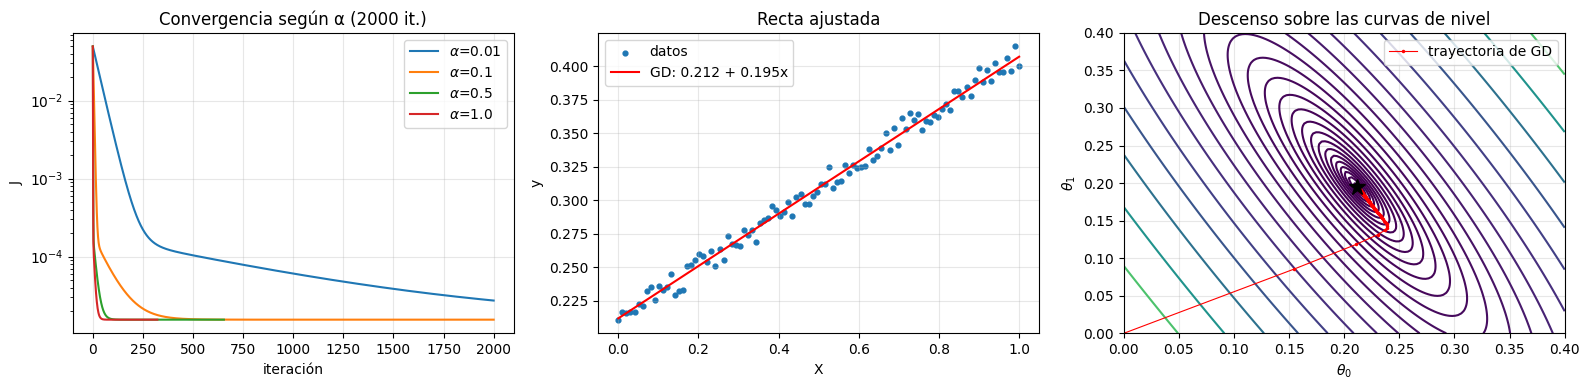

In [ ]:
# 12. regresion lineal con gradiente descendente
np.random.seed(0)
X = np.linspace(0, 1, 100)
y = 0.2 + 0.2 * X + 0.02 * np.random.random(100)

def hipotesis(theta, X):
    return theta[0] + theta[1] * X

def costo_gd(theta, X, y):
    return np.sum((hipotesis(theta, X) - y) ** 2) / (2 * len(y))

def gradiente(theta, X, y):
    # Forma matricial: grad J = (1/m) * Xd (Xd^T theta - y), con Xd de dimension (2, m).
    m = len(y)
    Xd = np.vstack([np.ones(m), X])
    return Xd @ (Xd.T @ theta - y) / m

def gd_regresion(X, y, theta0=(0.0, 0.0), alpha=0.5, n_iter=50_000, tol=1e-12):
    theta = np.array(theta0, float)
    hist_J, hist_theta = [costo_gd(theta, X, y)], [theta.copy()]
    for _ in range(n_iter):
        g = gradiente(theta, X, y)
        if np.linalg.norm(g) < tol:
            break
        theta = theta - alpha * g
        hist_J.append(costo_gd(theta, X, y)); hist_theta.append(theta.copy())
    return theta, np.array(hist_J), np.array(hist_theta)

th_t = np.array([0.1, 0.3]); eps = 1e-6
g_num = np.array([(costo_gd(th_t + eps * e, X, y) - costo_gd(th_t - eps * e, X, y)) / (2 * eps) for e in np.eye(2)])
print("gradiente numérico :", g_num, "\ngradiente analítico:", gradiente(th_t, X, y))

theta_gd, histJ, histTheta = gd_regresion(X, y)
print(f"GD: theta0={theta_gd[0]:.6f}, theta1={theta_gd[1]:.6f}, J={histJ[-1]:.3e}, iteraciones={len(histJ)-1}")

# estabilidad
H = np.array([[1, X.mean()], [X.mean(), (X**2).mean()]])
lam = np.linalg.eigvalsh(H)
print(f"autovalores de H: {lam.round(4)} | alpha máx. estable = 2/λmax = {2/lam.max():.3f} | número de condición = {lam.max()/lam.min():.1f}")

# efecto de alpha
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a in [0.01, 0.1, 0.5, 1.0]:
    _, hJ, _ = gd_regresion(X, y, alpha=a, n_iter=2000)
    ax[0].plot(hJ, label=fr"$\alpha$={a}")
ax[0].set_yscale("log"); ax[0].set_xlabel("iteración"); ax[0].set_ylabel("J")
ax[0].set_title("Convergencia según α (2000 it.)"); ax[0].legend()

ax[1].scatter(X, y, s=12, label="datos")
ax[1].plot(X, hipotesis(theta_gd, X), "r", label=fr"GD: {theta_gd[0]:.3f} + {theta_gd[1]:.3f}x")
ax[1].set_xlabel("X"); ax[1].set_ylabel("y"); ax[1].legend(); ax[1].set_title("Recta ajustada")

t0g = np.linspace(0.0, 0.4, 150); t1g = np.linspace(0.0, 0.4, 150)
T0, T1 = np.meshgrid(t0g, t1g)
JJ = costo_malla(T0, T1, X, y)
ax[2].contour(T0, T1, JJ, levels=np.geomspace(JJ.min() + 1e-6, JJ.max(), 25), cmap="viridis")
ax[2].plot(histTheta[:300, 0], histTheta[:300, 1], "r.-", ms=3, lw=0.8, label="trayectoria de GD")
ax[2].plot(*theta_gd, "k*", ms=12)
ax[2].set_xlabel(r"$\theta_0$"); ax[2].set_ylabel(r"$\theta_1$"); ax[2].set_title("Descenso sobre las curvas de nivel"); ax[2].legend()
plt.tight_layout(); plt.show()

                             theta0     theta1        MSE         R²
Gradiente descendente    0.21195706 0.19499763 0.00003112 0.99046522
sklearn LinearRegression 0.21195706 0.19499763 0.00003112 0.99046522
Solución cerrada         0.21195706 0.19499763 0.00003112 0.99046522
Diferencia máx. |θ_GD − θ_sklearn| = 1.3052503522459347e-11


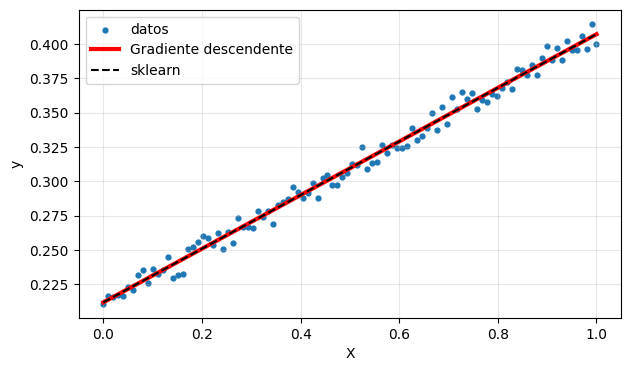

13. Conclusion:
Los parámetros del gradiente descendente coinciden con los de sklearn (que resuelve el problema por mínimos cuadrados con álgebra lineal)
Como J es convexa, GD converge al mismo mínimo global único que la solución cerrada.


In [ ]:
# 13. comparacion con LinearRegression de sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression().fit(X.reshape(-1, 1), y)
y_gd = hipotesis(theta_gd, X)
y_sk = lr.predict(X.reshape(-1, 1))
c0, c1 = ajuste(X, y)

tabla = pd.DataFrame({
    "theta0": [theta_gd[0], lr.intercept_, c0],
    "theta1": [theta_gd[1], lr.coef_[0], c1],
    "MSE": [mean_squared_error(y, y_gd), mean_squared_error(y, y_sk), mean_squared_error(y, c0 + c1 * X)],
    "R²": [r2_score(y, y_gd), r2_score(y, y_sk), r2_score(y, c0 + c1 * X)],
}, index=["Gradiente descendente", "sklearn LinearRegression", "Solución cerrada"])
pd.options.display.float_format = "{:.8f}".format
print(tabla)
pd.reset_option("display.float_format")

print("Diferencia máx. |θ_GD − θ_sklearn| =", np.max(np.abs(theta_gd - np.array([lr.intercept_, lr.coef_[0]]))))

plt.scatter(X, y, s=12, label="datos")
plt.plot(X, y_gd, "r", lw=3, label="Gradiente descendente")
plt.plot(X, y_sk, "k--", lw=1.5, label="sklearn")
plt.legend(); plt.xlabel("X"); plt.ylabel("y"); plt.show()

print("13. Conclusion:")
print("Los parámetros del gradiente descendente coinciden con los de sklearn (que resuelve el problema por mínimos cuadrados con álgebra lineal)")
print("Como J es convexa, GD converge al mismo mínimo global único que la solución cerrada.")

In [ ]:
#14. empaquetado como libreria de python en el zip.
!unzip -q regresion_lineal_gd.zip
!pip install -q ./regresion_lineal_gd

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


FitResult(theta0=0.21195706365894007, theta1=0.19499762626355863, cost=1.5559843381403063e-05, n_iter=654)
Predicción para X=[0.25, 0.5, 0.75]: [0.26070647 0.30945588 0.35820528]
Coste en la solución: 1.5559843381403063e-05


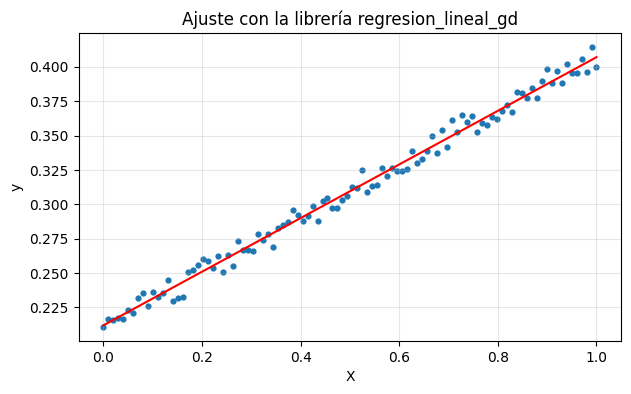

In [ ]:
from regresion_lineal_gd import fit, cost_function, hypothesis

np.random.seed(0)
X = np.linspace(0, 1, 100)
y = 0.2 + 0.2 * X + 0.02 * np.random.random(100)

res = fit(X, y, alpha=0.5, n_iter=50_000, tol=1e-12)
print(res)
print("Predicción para X=[0.25, 0.5, 0.75]:", res.predict([0.25, 0.5, 0.75]))
print("Coste en la solución:", cost_function(X, y, res.theta))

plt.scatter(X, y, s=12); plt.plot(X, res.predict(X), "r")
plt.title("Ajuste con la librería regresion_lineal_gd"); plt.xlabel("X"); plt.ylabel("y"); plt.show()